# FT09 – portable Baseline

Pro Zug werden Klickkoordinaten, Vorher-/Nachher-Bilder und Levelstatus angezeigt. Level 1–5 gehören zum Projektvergleich; Level 6 ist zusätzlich spielbar.


In [1]:
%pip install -q "arc-agi==0.9.9" pillow matplotlib openai

Note: you may need to restart the kernel to use updated packages.


In [2]:
from contextlib import chdir
from pathlib import Path
import os

# 1. Lokales Spiel und Darstellung
import arc_agi
import matplotlib.pyplot as plt
import numpy as np
from arc_agi import OperationMode
from arc_agi.rendering import frame_to_rgb_array
from PIL import Image

# Automatischer Cache: kein benutzerspezifischer Pfad nötig.
CACHE_DIR = (Path.cwd() / ".ft09_cache").resolve()
ENVIRONMENTS_DIR = CACHE_DIR / "environment_files"
RECORDINGS_DIR = CACHE_DIR / "recordings"
ENVIRONMENTS_DIR.mkdir(parents=True, exist_ok=True)
RECORDINGS_DIR.mkdir(parents=True, exist_ok=True)

def frame_to_image(observation, scale=8):
    """Render the newest frame of an observation as a PIL image."""
    pixels = frame_to_rgb_array(
        steps=0,
        frame=observation.frame[-1],
        scale=scale,
    )
    return Image.fromarray(pixels)



class FT09Game:
    """Convenience wrapper around the FT09 environment."""

    def __init__(self, arcade, game_id="ft09"):
        self.env = arcade.make(game_id)
        if self.env is None:
            raise RuntimeError(
                "FT09 konnte nicht geladen werden. Prüfe die Internetverbindung "
                "und die vorherigen ARC-SDK-Meldungen."
            )
        self.actions = {a.name: a for a in self.env.action_space}
        self.obs = None

    def reset(self):
        self.obs = self.env.reset()
        return self.obs

    def step(self, x, y):
        self.obs = self.env.step(
            self.actions["ACTION6"],
            data={"x": x, "y": y},
        )
        return self.obs

    def render(self, scale=8):
        return frame_to_image(self.obs, scale=scale)

    def done(self):
        return self.obs.state.name in {"WIN", "GAME_OVER"}

In [3]:
# 2. Modell und Baseline-Prompt
from getpass import getpass
from openai import OpenAI

# Voreinstellungen für den bisherigen Modellanbieter.
API_BASE_URL = "https://chat-1.ki-awz.iisys.de/api"
MODEL = "lisa-pro"

API_KEY = getpass("API-Key:").strip()
if not API_KEY:
    raise ValueError("Kein API-Key eingegeben. Führe diese Zelle erneut aus.")

client = OpenAI(base_url=API_BASE_URL, api_key=API_KEY)
del API_KEY
print("Success")

import base64
import io


def image_to_data_uri(image):
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
    return "data:image/png;base64," + encoded



GAME_PROMPT = """You are playing FT09, an ARC-AGI-3 game. Your goal is to solve the current level.
Use the current board and the history of previous clicks to infer the goal and choose one next click.
Look for relationships among the visible patterns and which parts of the board can be changed.
Use the effects of earlier clicks to guide your next choice. Avoid repeating an ineffective click when the board has not changed.

The available action is ACTION6, a click at (x, y) on a 64 by 64 grid.
Use integer coordinates from 0 to 63. x increases to the right and y increases downward.
Use game-grid coordinates even when the board image is enlarged.

Reply with exactly one line in the format ACTION6 x y."""


import re


def ask_llm_for_move(image, history, prompt):
    """Return click coordinates (x,y), or None if the answer was unusable."""
    message = "Choose the next click for the current board."
    if history:
        message += "\n\nPrevious clicks: " + ", ".join(history)

    response = client.with_options(
        timeout=90.0, 
        max_retries=0,
    ).chat.completions.create(
        model=MODEL,
        messages=[{"role": "system", "content": prompt}, {
            "role": "user",
            "content": [
                {"type": "text", "text": message},
                {"type": "image_url", "image_url": {"url": image_to_data_uri(image)}},
            ],
        }],
    )

    text = response.choices[0].message.content or ""
    match = re.fullmatch(r"ACTION6\s+([0-9]{1,2})\s+([0-9]{1,2})", text.strip().upper())
    if match is None:
        # Zeigt den Modelltext, wenn der Parser keinen Klick erkennt.
        print("Ungültige Modellantwort:", repr(text))
        return None

    x, y = map(int, match.groups())
    if not (0 <= x < 64 and 0 <= y < 64):
        print("Koordinaten außerhalb des Spielfelds:", repr(text))
        return None

    return x, y

API-Key: ········


Success


In [4]:
# 3. Spielschleife und Level-Auswahl
def play_with_llm(game, prompt, max_steps=15):
    print("Setze FT09 zurück …", flush=True)
    obs = game.reset()
    history = []
    initial_completed = obs.levels_completed

    for step in range(max_steps):
        print("Erzeuge das Spielfeldbild …", flush=True)
        image = game.render(scale=2)

        print(f"Step {step + 1}/{max_steps}", flush=True)
        print("Game state:", obs.state)
        print("Levels completed:", obs.levels_completed)
        print("Previous actions:", history)

        print("Warte auf Modellantwort …", flush=True)
        move = ask_llm_for_move(image, history, prompt)
        if move is None:
            print("Das Modell hat keinen gültigen Klick zurückgegeben.")
            break

        x, y = move
        action = f"ACTION6 {x} {y}"
        print("Model chose:", action, flush=True)

        # Sichert das Vorher-Bild für die Klickmarkierung und den Zellvergleich.
        before_grid = obs.frame[-1].copy()
        obs = game.step(x, y)
        print("Geänderte Zellen:", int(np.count_nonzero(before_grid != obs.frame[-1])))
        history.append(action)

        print("Game state after click:", obs.state)
        print("Levels completed after click:", obs.levels_completed)
        fig, axes = plt.subplots(1, 2, figsize=(8, 4))
        extent = (-0.5, 63.5, 63.5, -0.5)
        axes[0].imshow(image, interpolation="nearest", extent=extent)
        axes[0].scatter(x, y, marker="x", color="lime", s=100) # marker to see where the model clicked exactly
        axes[0].set_title(f"Vorher · Klick ({x}, {y})")
        axes[1].imshow(game.render(scale=2), interpolation="nearest", extent=extent)
        axes[1].set_title("Nachher")
        fig.tight_layout()
        plt.show()
        plt.close(fig)

        if obs.levels_completed > initial_completed:
            print(f"Level gelöst nach {len(history)} Aktionen.")
            break

        if game.done():
            break

    return history


from copy import copy

LEVEL_ACTION_LIMIT = 15

os.environ["OPERATION_MODE"] = "normal"

with chdir(ENVIRONMENTS_DIR.parent):
    level_arcade = arc_agi.Arcade(
        operation_mode=OperationMode.NORMAL,
        environments_dir=str(ENVIRONMENTS_DIR),
        recordings_dir=str(RECORDINGS_DIR),
    )


class FT09SingleLevel(FT09Game):
    def __init__(self, level_number):
        if not isinstance(level_number, int) or not 1 <= level_number <= 6:
            raise ValueError("Wähle ein Level von 1 bis 6.")
        # Lokale Metadaten können Pfade relativ zum Umgebungsordner enthalten.
        with chdir(ENVIRONMENTS_DIR.parent):
            super().__init__(level_arcade)
        self.level_number = level_number

    def reset(self):
        start = super().reset()
        # Der lokale SDK-Wrapper stellt die Spielinstanz über _game bereit.
        engine = self.env._game
        engine.set_level(self.level_number - 1)
        self.obs = copy(start)
        self.obs.frame = [engine.camera.render(engine.current_level.get_sprites())]
        return self.obs


def play_ft09_level(level_number):
    print(f"FT09 · Level {level_number}", flush=True)
    level_game = FT09SingleLevel(level_number)
    return play_with_llm(
        level_game, GAME_PROMPT, max_steps=LEVEL_ACTION_LIMIT
    )

INFO:arc_agi.scorecard:Initialized ScorecardManager with idle_for=0:15:00 and max_open_for=3 days, 0:00:00
2026-11-10 16:54:44 | INFO | Got anonymous API key: 2479e918-4b5d-40fa-916c-162e8b48b1c0
2026-11-10 16:54:44 | INFO | You can register for an API key at https://three.arcprize.org
2026-11-10 16:54:45 | INFO | Successfully fetched 25 environment(s) from API


FT09 · Level 1
2026-11-10 16:54:45 | INFO | Created new scorecard: 91b492b1-7efe-42d9-b81e-a8a58dd62836
2026-11-10 16:54:45 | INFO | Successfully fetched metadata for game ft09
2026-11-10 16:54:45 | INFO | Successfully loaded game class Ft09 from /home/jovyan/FT09/.ft09_cache/environment_files/ft09/0d8bbf25/ft09.py
Setze FT09 zurück …
Erzeuge das Spielfeldbild …
Step 1/15
Game state: GameState.NOT_FINISHED
Levels completed: 0
Previous actions: []
Warte auf Modellantwort …
Model chose: ACTION6 46 14
Geänderte Zellen: 0
Game state after click: GameState.NOT_FINISHED
Levels completed after click: 0


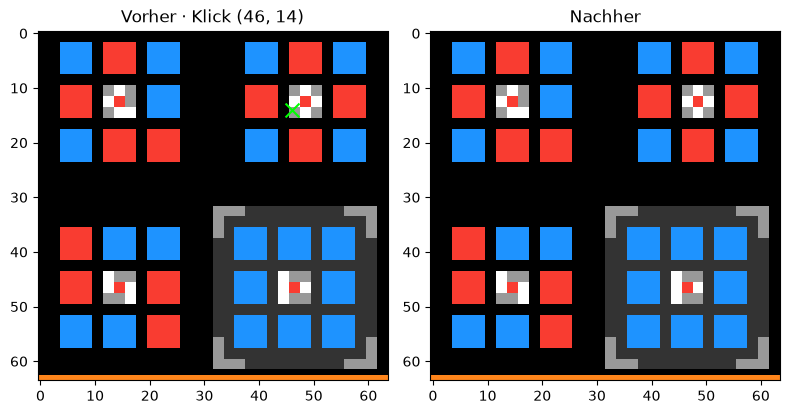

Erzeuge das Spielfeldbild …
Step 2/15
Game state: GameState.NOT_FINISHED
Levels completed: 0
Previous actions: ['ACTION6 46 14']
Warte auf Modellantwort …


In [ ]:
# Level 1
level_1_actions = play_ft09_level(1)

In [ ]:
# Level 2
level_2_actions = play_ft09_level(2)

In [ ]:
# Level 3
level_3_actions = play_ft09_level(3)

In [ ]:
# Level 4
level_4_actions = play_ft09_level(4)

In [ ]:
# Level 5
level_5_actions = play_ft09_level(5)

In [ ]:
# Level 6
level_6_actions = play_ft09_level(6)